[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/multigeom/multigeom-tutorials/blob/steeve-g/notebooks/16_whitening_stimulus_features.ipynb)

# Whitening experiment: stimulus features of a whitened image prior

* **Author**: laquitainesteeve@gmail.com

* **Goal**: See how spatially whitening the images changes the stimulus features $M_t^{\rm env}(x)$ of task 2 (notebook 8). Natural images have most of their variance at low spatial frequencies; whitening flattens their power spectrum, as the centre–surround receptive fields of the retina do. In steps:
  1. whiten the images with the filter of Olshausen & Field (1996), check it against the power spectrum of the training images, and check that the whitened images still look like the images;
  2. train a diffusion model of the same type as notebook 8's on the whitened images, without responses;
  3. estimate the denoised image $\hat x(x_t)$ from its null token;
  4. compute the stimulus features of the whitened images and compare them with notebook 8's.

* **Status**: steps 1 to 4.

* **Requirements**: TinyImageNet, the V1 checkpoints (downloaded below), the model trained in step 2 (`scripts/train_whitened_diffusion.py`, about 7 h on one GPU), a GPU, `multigeom` from the `g-per-scale` branch.

* **Time**: about 1 min for step 1 and 30 min for step 4 (the stored results are reloaded in seconds).

## 1. Setup

### 1.1. Install package

Install the version of `multigeom` this notebook needs, the `g-per-scale` branch on GitHub: on Google Colab always (with `diffusers`), elsewhere only if the installed one lacks its functions.

In [1]:
%%time

# the multigeom this notebook needs: the g-per-scale branch on GitHub, until it is
# released (without its dependencies: Colab already has torch, numpy, scipy and
# matplotlib, and reinstalling torch is slow and can break the GPU runtime)
import os
import sys

BRANCH = "git+https://github.com/multigeom/multigeom.git@g-per-scale"

# on Google Colab: install the latest commit of that branch (forced: pip skips a
# branch it installed before, even if the branch has changed since), and the
# diffusion models' library
if "google.colab" in sys.modules:
    %pip install -q --no-deps --force-reinstall {BRANCH}
    %pip install -q "diffusers>=0.30,<0.38"

    # an older multigeom imported earlier in this session stays in memory: restart
    # the session so that the next cells import the new one (then run them from the
    # next cell on)
    if "multigeom" in sys.modules:
        print("restarting the session to load the new multigeom: run the next cells")
        os.kill(os.getpid(), 9)

# on your own machine: install that branch only if the installed multigeom lacks its
# functions (this replaces an editable install; restart the kernel afterwards)
else:
    import multigeom

    if not hasattr(multigeom.analysis, "compute_bootstrap"):
        %pip install -q --no-deps {BRANCH}
        print("installed multigeom from the g-per-scale branch: restart the kernel")

CPU times: user 3.16 s, sys: 79.9 ms, total: 3.24 s
Wall time: 630 ms


### 1.2. Imports and parameters

Work from the repository root, import the packages, and set the parameters: the training images, the cut-off of the filter, the example images, and where the results and figures go.

<details><summary>Details</summary>

* `estimate_power_spectrum` gives the radially averaged power spectrum of images, `fit_power_law` its exponent, and `WhiteningFilter` the whitening filter of Olshausen & Field (all in `multigeom.datasets`). `plot_whitening_spectra`, `plot_whitening_kernel` and `plot_whitening_examples` draw the figures (`multigeom.plotting`).

</details>

In [2]:
%%time

import os
from pathlib import Path

import copy
import json

import matplotlib.pyplot as plt
import torch
from huggingface_hub import snapshot_download

# move to the repository root (the folder containing environment.yml): data/ and
# assets/ are read and written from there
root = Path.cwd().resolve()
while not (root / "environment.yml").exists() and root != root.parent:
    root = root.parent

if (root / "environment.yml").exists():
    os.chdir(root)

print("repo root:", root)

from multigeom.config import load_config
from multigeom.datasets import (
    CANONICAL_TRANSFORM,
    TinyImageNetDataset,
    WhiteningFilter,
    download_tinyimagenet,
    estimate_power_spectrum,
    fit_power_law,
    load_examples,
)
from multigeom.diffusion import compute_denoised
from multigeom.diffusion.model import build_diffusion_model, build_scheduler
from multigeom.pipeline.metric_field import load_models
from multigeom.pipeline.per_scale import compute_env
from multigeom.plotting import (
    plot_denoised,
    plot_per_scale,
    plot_training_loss,
    plot_whitening_examples,
    plot_whitening_kernel,
    plot_whitening_spectra,
)
from multigeom.utils import get_device, load_intermediate, save_intermediate

# the parameters of this notebook
PARAMS = {
    # the training images of the filter: the first images_per_class of each of the 200
    # classes of the TinyImageNet training set (64 x 64, gray, in [-1, 1])
    "images_per_class": 50,
    # the band (cycles/pixel) where the power spectrum is fitted with A / f^alpha: above
    # the lowest frequencies (few samples, smeared by the window) and below the noise
    # floor (JPEG, aliasing) that flattens the spectrum above about 0.3
    "fit_band": (0.04, 0.25),
    # the cut-off f0 of the filter of Olshausen & Field (cycles/pixel), theirs, and the
    # reflection padding of the images before filtering (pixels)
    "cutoff": 0.4,
    "pad": 16,
    # the example images of notebook 8: the frog, then test images by their index
    "frog": "data/tiny-imagenet-200/train/n01644900/images/n01644900_0.JPEG",
    "test_images": [0, 3, 9, 16, 27, 41, 58, 72, 95, 118, 150, 187],
    "n_shown": 6,
    # the model of notebook 8 (the null token of the inception V1 model), and the model
    # trained on the whitened images (step 2)
    "encoder": "inception",
    "prior_area": "V1",
    "whitened_model": "runs/diffusion/unconditional/tinyimagenet-whitened",
    # the DDPM steps of the check of the denoised images (step 3)
    "denoise_steps": [40, 200, 400, 600, 800],
    # the stimulus features, as in notebook 8: probes per noise scale, noisy images per
    # probe, finite-difference step in units of √t, shift of the seeds, and leading
    # eigenvectors kept and drawn
    "n_samples": 200,
    "n_noisy": 8,
    "eta": 0.02,
    "env_seed_offset": 100_000,
    "n_eigvecs": 4,
    # the stored stimulus features (True: recompute and overwrite them), and the images
    # whose figures stay in the notebook (each is about 1 MB)
    "recompute": False,
    "show": ["frog"],
    # where the filter is stored and the figures are saved, and their resolution in
    # the file and on screen
    "intermediate_dir": "data/02_intermediate/16_whitening",
    "figure_dir": "assets/figures/stimulus_whitening/stimulus_features",
    "file_dpi": 200,
    "screen_dpi": 100,
}

# the diffusion and estimator configs (packaged with multigeom), and the device
diff_cfg = load_config("diffusion")
est_cfg = load_config("estimator")
device = get_device(None)
print("device:", device)
figure_dir = Path(PARAMS["figure_dir"])
figure_dir.mkdir(parents=True, exist_ok=True)

repo root: /home/steeve/steeve/idv/code/proj_multigeom/multigeom-tutorials


device: cuda
CPU times: user 954 ms, sys: 159 ms, total: 1.11 s
Wall time: 1.12 s


## 2. Download the models and datasets

The checkpoints of the V1 model (the model of notebook 8) are on Hugging Face; TinyImageNet gives the training images of the filter and the example images (240 MB the first time).

In [3]:
%%time

# the checkpoints (files already there are kept; the older checkpoints and the retina
# models are skipped), and TinyImageNet (nothing if already there)
snapshot_download(
    repo_id="steevelaquitaine/multigeom",
    local_dir="runs",
    ignore_patterns=["archive/*", "*/lorenzi/*"],
)
download_tinyimagenet()

Fetching 21 files:   0%|          | 0/21 [00:00<?, ?it/s]

README.md: 0.00B [00:00, ?B/s]

CPU times: user 244 ms, sys: 37.4 ms, total: 281 ms
Wall time: 956 ms


PosixPath('/home/steeve/steeve/idv/code/proj_multigeom/multigeom-tutorials/data/tiny-imagenet-200')

## 3. Step 1: design the whitening filter

### 3.1. The power spectrum of the training images

The power at each spatial frequency, averaged over the training images and over the directions, and its power-law fit $S(f) = A / f^\alpha$.

<details><summary>Details</summary>

* Each image minus its mean is apodised by a 2-D Hann window before its Fourier transform: without it, the jump between opposite edges of the image adds spurious power along the axes of the spectrum.
* The fit is a least-squares line on a log–log scale, within `PARAMS["fit_band"]`. The filter of Olshausen & Field assumes $\alpha = 2$; the fit tells how far our images are from that.

</details>

In [4]:
%%time

# the training images of the filter, [n, 1, 64, 64] in [-1, 1]
train = TinyImageNetDataset(
    split="train",
    transform=CANONICAL_TRANSFORM,
    images_per_class=PARAMS["images_per_class"],
)
images = torch.stack([train[index] for index in range(len(train))])

# their power spectrum and its power-law fit
freqs, power = estimate_power_spectrum(images)
amplitude, exponent = fit_power_law(freqs, power, PARAMS["fit_band"])
print(f"{len(images)} images; S(f) = {amplitude:.3g} / f^{exponent:.2f}")

10000 images; S(f) = 0.00309 / f^2.33
CPU times: user 8.46 s, sys: 2.09 s, total: 10.6 s
Wall time: 1.97 s


### 3.2. The whitening filter of Olshausen & Field

The filter of Olshausen & Field (1996), $K(f) = f\, e^{-(f/f_0)^4}$ with $f_0 = 0.4$ cycles/pixel: it multiplies the amplitude spectrum, which falls as $1/f$, by $f$, which flattens it (whitening), and its exponential cuts off the frequencies near the top of the spectrum, where the images carry little signal and much noise. The filter is scaled so the whitened images keep the pixel variance of the images.

<details><summary>Details</summary>

* The filter whitens a spectrum $1/f^2$ exactly; panel A tests that assumption on our images.
* It is the filter of Atick & Redlich (1992) in its simplest form: whitening at low frequencies, times a low-pass, which in the retina is the optics of the eye. Without the low-pass, $K = f$ at all frequencies would amplify the noise floor above about 0.3 cycles/pixel and make the images look like speckle; with it, the spatial kernel is a compact centre with a negative surround.
* $K(0) = 0$: the mean of each image is removed. $K$ peaks at $f_0/4^{1/4} \approx 0.28$ cycles/pixel.
* The images are padded by reflection before filtering, so the filter does not wrap one edge of the image onto the other.
* Panel C shows the spectrum of the whitened images: flat below the cut-off if the images are white there. Panel D shows the pixel values: whitened images are not bounded to [-1, 1], which matters for the diffusion model (step 2).

</details>

scale 2.93
whitened power max/min from 0.04 to 0.12 cycles/pixel: 1.80
CPU times: user 25.4 s, sys: 10.1 s, total: 35.5 s
Wall time: 2.76 s


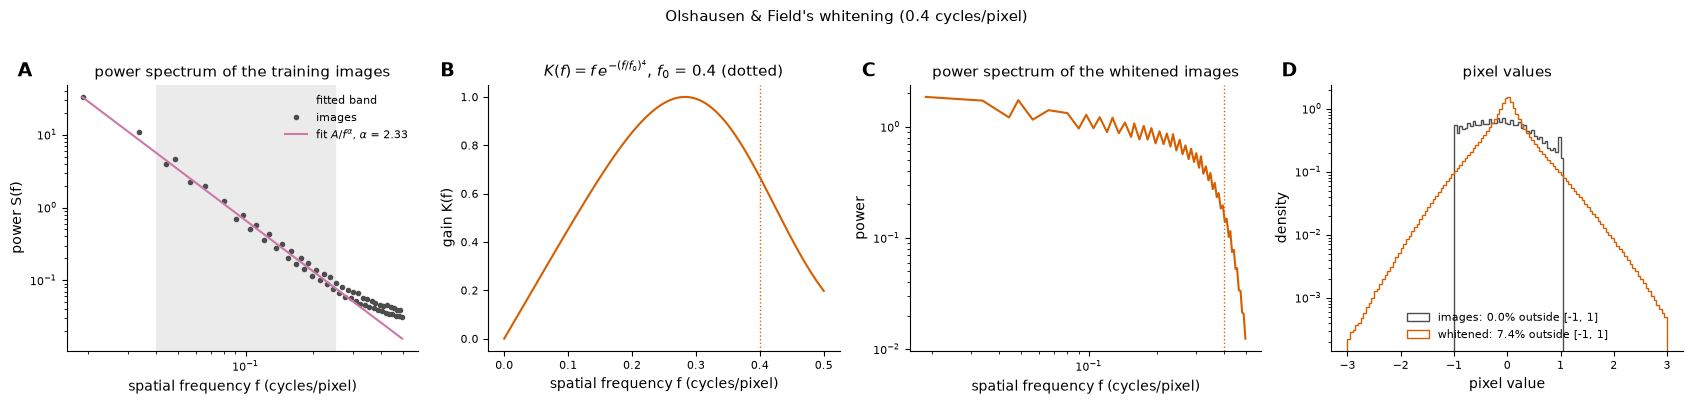

In [5]:
%%time

# 1. the filter, scaled to keep the pixel variance of the images
whitening = WhiteningFilter.from_images(images, PARAMS["cutoff"], PARAMS["pad"])

# 2. the spectrum and the pixel values of the whitened images
whitened = whitening(images)
whitened_spectrum = estimate_power_spectrum(whitened)
pixels = {"images": images, "whitened": whitened}

# 3. the figure, also saved
fig, _ = plot_whitening_spectra(
    (freqs, power),
    (amplitude, exponent),
    PARAMS["fit_band"],
    whitening,
    whitened_spectrum,
    pixels,
    PARAMS,
)
fig.savefig(figure_dir / "spectra.png", dpi=PARAMS["file_dpi"], bbox_inches="tight")

# 4. the flatness of the whitened spectrum well below the cut-off, and the scale
w_freqs, w_power = whitened_spectrum
below = w_power[(w_freqs >= 0.04) & (w_freqs <= 0.3 * PARAMS["cutoff"])]
print(f"scale {whitening.scale:.2f}")
ratio = float(below.max() / below.min())
print(f"whitened power max/min from 0.04 to 0.12 cycles/pixel: {ratio:.2f}")

### 3.3. The spatial kernel

The filter as a convolution kernel: the image is replaced, at each pixel, by the weighted sum of its neighbours with these weights. A centre–surround kernel subtracts from each pixel a local average of its surround.

CPU times: user 170 ms, sys: 4.69 ms, total: 175 ms
Wall time: 81.1 ms


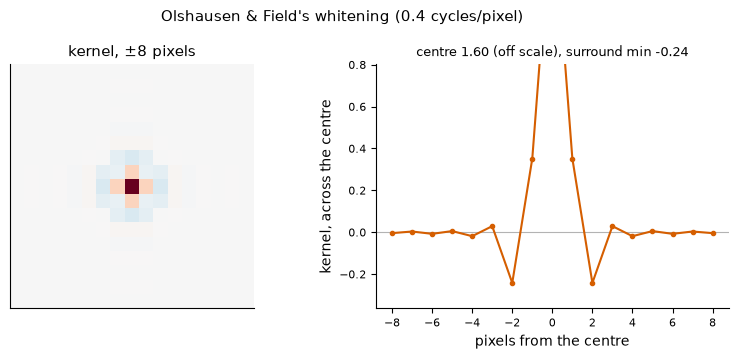

In [6]:
%%time

fig, kernel = plot_whitening_kernel(whitening, PARAMS)
fig.savefig(figure_dir / "kernel.png", dpi=PARAMS["file_dpi"], bbox_inches="tight")

### 3.4. Do the whitened images still look like the images?

The frog and test images of notebook 8, raw and whitened. The whitened images are drawn in gray from $-m$ to $m$, $m$ the 99.5th percentile of their absolute values, so a few bright edges do not wash out the rest.

CPU times: user 1.81 s, sys: 0 ns, total: 1.81 s
Wall time: 325 ms


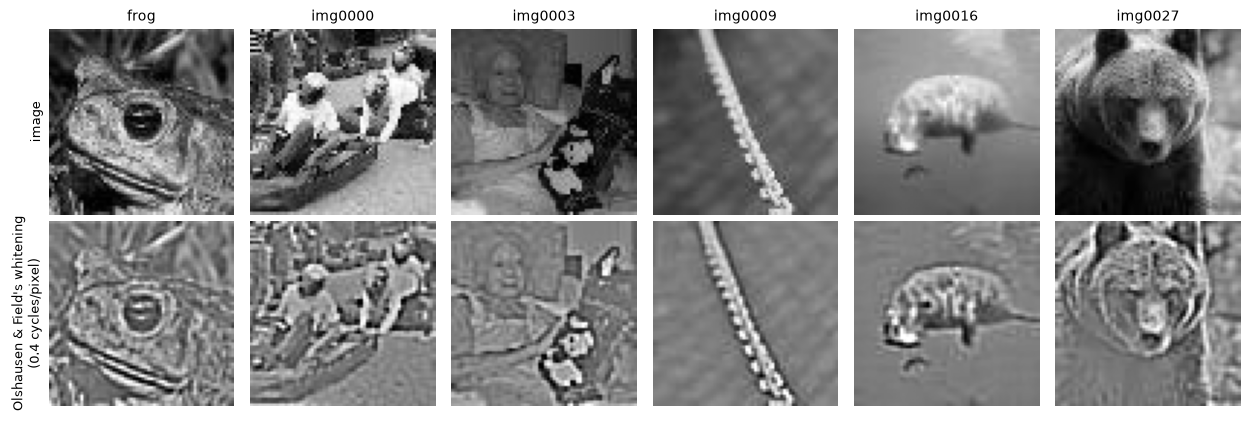

In [7]:
%%time

# the example images, and the figure, also saved
examples = load_examples(PARAMS, int(est_cfg.seed))
shown = {
    name: image for name, (image, _) in list(examples.items())[: PARAMS["n_shown"]]
}
fig, _ = plot_whitening_examples(shown, whitening, PARAMS)
fig.savefig(figure_dir / "examples.png", dpi=PARAMS["file_dpi"], bbox_inches="tight")

### 3.5. Store the filter

The filter (its cut-off, scale and padding) goes to `data/02_intermediate/16_whitening/filter.pt`, for training (step 2) and for whitening the example images (step 4).

In [8]:
%%time

intermediate_dir = Path(PARAMS["intermediate_dir"])
intermediate_dir.mkdir(parents=True, exist_ok=True)
torch.save(whitening.state_dict(), intermediate_dir / "filter.pt")
print(whitening.state_dict())

{'cutoff': 0.4, 'scale': 2.933501482363829, 'pad': 16}
CPU times: user 753 μs, sys: 260 μs, total: 1.01 ms
Wall time: 937 μs


## 4. Step 2: the model of the whitened images

A diffusion model of the type of notebook 8's (the network and training recipe of the V1 model: 100,000 TinyImageNet training images, 200 epochs), trained on the whitened images without responses: every training step sees the null token, so its null token is the unconditional model of the whitened images, as that of the V1 model is of the images. It is trained by `scripts/train_whitened_diffusion.py` (about 7 h on one GPU), outside this notebook; this section loads it and draws its training loss next to that of the V1 model.

<details><summary>Details</summary>

* `multigeom.diffusion.train.train_unconditional` trains with zero responses, without observation noise or dropout.
* The whitened images are harder to denoise than the images (the strong correlations between neighbouring pixels, which help to predict a pixel from its neighbours, are gone), so the final loss is expected to be higher.

</details>

CPU times: user 1.05 s, sys: 190 ms, total: 1.24 s
Wall time: 905 ms


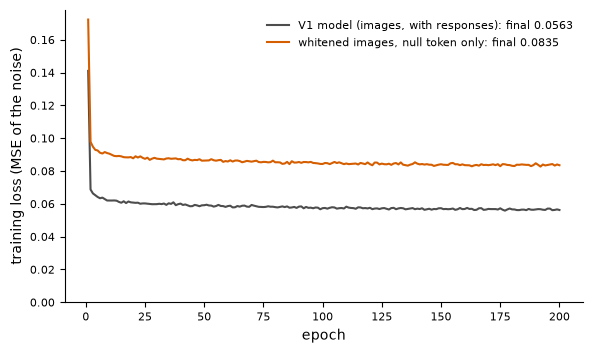

In [9]:
%%time

# 1. the model of the whitened images (stop here if it is not trained yet)
model_dir = Path(PARAMS["whitened_model"])
if not (model_dir / "final_model.pt").exists():
    raise FileNotFoundError(
        "train the model first: python scripts/train_whitened_diffusion.py"
    )
whitened_unet = build_diffusion_model(diff_cfg).to(device)
stored = torch.load(
    model_dir / "final_model.pt", map_location=device, weights_only=False
)
whitened_unet.load_state_dict(stored["model_state_dict"])
whitened_unet.eval()

# 2. the model of notebook 8, and the noise schedule of both
_, raw_unet, _ = load_models(
    PARAMS["encoder"], PARAMS["prior_area"], Path("runs"), None, diff_cfg, True, device
)
alphas_cumprod = build_scheduler(diff_cfg).alphas_cumprod.to(device)

# 3. the training losses, also saved
area_dir = Path("runs/diffusion") / PARAMS["encoder"] / PARAMS["prior_area"]
histories = {
    "V1 model (images, with responses)": json.load(open(area_dir / "train_log.json")),
    "whitened images, null token only": json.load(open(model_dir / "train_log.json")),
}
fig, final = plot_training_loss(histories, PARAMS)
fig.savefig(
    figure_dir / "training_loss.png", dpi=PARAMS["file_dpi"], bbox_inches="tight"
)

## 5. Step 3: the denoised image from the null token

`compute_denoised` gives the denoised image $\hat x(x_t) = (x_t - \sqrt{1 - \bar\alpha_t}\, \hat\epsilon(x_t)) / \sqrt{\bar\alpha_t}$ (Tweedie's formula) from the noise $\hat\epsilon$ that the null token predicts. As a check, the whitened frog noised at 5 noise scales and denoised by the model of the whitened images: at fine noise scales $\hat x$ should be close to the image, and at coarse ones a blurred guess of it.

<details><summary>Details</summary>

* $\hat x$ is not clipped to [-1, 1] (`clamp=False`, the default): whitened images are not bounded to it.
* The image and the denoised images share one gray scale; each noisy image has its own.

</details>

CPU times: user 447 ms, sys: 62 ms, total: 509 ms
Wall time: 387 ms


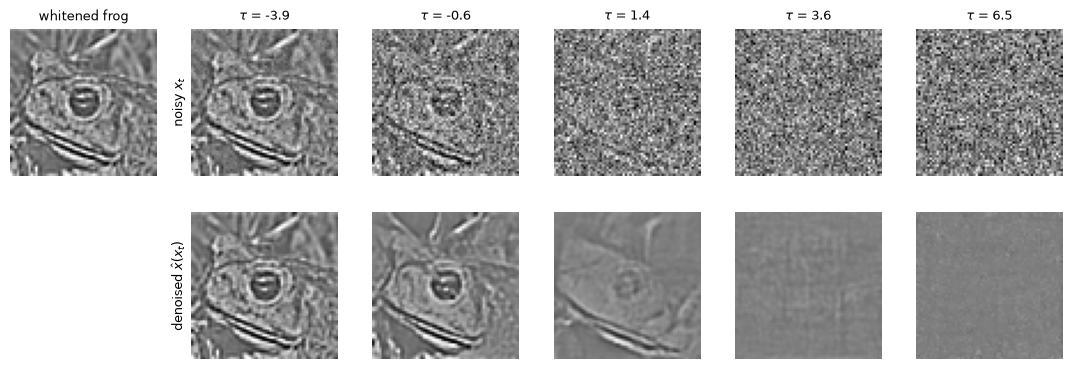

In [10]:
%%time

# 1. the whitened frog, noised at each step with a seeded noise
examples = load_examples(PARAMS, int(est_cfg.seed))
frog = whitening(examples["frog"][0]).to(device)
generator = torch.Generator(device=device).manual_seed(int(est_cfg.seed))
noisy, denoised = {}, {}
with torch.no_grad():
    for t_j in PARAMS["denoise_steps"]:
        ab = alphas_cumprod[t_j]
        noise = torch.randn(frog.shape, device=device, generator=generator)
        x_t = ab.sqrt() * frog + (1 - ab).sqrt() * noise
        scale = float(((1 - ab) / ab).log())
        noisy[scale] = x_t.cpu()
        denoised[scale] = compute_denoised(whitened_unet, x_t, t_j, alphas_cumprod)[
            0
        ].cpu()

# 2. the figure, also saved
fig, _ = plot_denoised(frog.cpu(), noisy, denoised, "whitened frog", PARAMS)
fig.savefig(figure_dir / "denoised.png", dpi=PARAMS["file_dpi"], bbox_inches="tight")

## 6. Step 4: the stimulus features of the images and of the whitened images

The stimulus features $M_t^{\rm env}(x)$ at each noise scale, as in notebook 8, for the frog and the 12 test images: from the null token of the V1 model on the images (notebook 8's), and from the null token of the model of the whitened images on the same images whitened. One figure per image, saved to `assets/figures/stimulus_whitening/stimulus_features/stimulus_features_<image>.png`; only those of `PARAMS["show"]` stay in the notebook.

<details><summary>Details</summary>

* The estimator and its settings are those of notebook 8 (200 probes per noise scale, 8 noisy images per probe, η = 0.02), with the same seeds, so the two rows of features differ only by the images and the model.
* **What the whitened features are.** They are directions in the space of the whitened images: the eigenvector shows the change of the whitened image that the model's denoised image follows most. They are not directly the changes of the raw image.
* The eigenvalues of both are drawn as they are (not normalized), on one linear axis.
* The results are stored in `data/02_intermediate/16_whitening/stimulus_features.pt` and reloaded on later runs.

</details>

In [11]:
%%time

# 1. estimator settings: those of the paper, with n_samples probes per noise scale and
# the n_eigvecs leading eigenpairs kept at each scale
cfg = copy.deepcopy(est_cfg)
cfg.monte_carlo.n_samples = PARAMS["n_samples"]
cfg.top_k = PARAMS["n_eigvecs"]

# 2. the example images, whitened, with the same seeds
whitened_examples = {
    name: (whitening(image), seed) for name, (image, seed) in examples.items()
}

# 3. the stimulus features of both, reloaded if stored, else computed and stored
env_file = Path(PARAMS["intermediate_dir"]) / "stimulus_features.pt"
if env_file.exists() and not PARAMS["recompute"]:
    env = load_intermediate(env_file)
else:
    env = {
        "images": compute_env(examples, raw_unet, alphas_cumprod, cfg, device, PARAMS),
        "whitened": compute_env(
            whitened_examples, whitened_unet, alphas_cumprod, cfg, device, PARAMS
        ),
    }
    save_intermediate(env, env_file)
print("stimulus features done:", len(env["images"]), "images")

stimulus features done: 13 images
CPU times: user 26min 26s, sys: 278 ms, total: 26min 26s
Wall time: 26min 26s


### 6.1. Plot the stimulus features

Each figure has the image and its whitened version (A), the leading 4 eigenvectors of the stimulus features at each noise scale for the images (B, notebook 8's) and for the whitened images (C), from the finest noise scale (left) to the coarsest (right), and their eigenvalues (D).

13 figures saved in assets/figures/stimulus_whitening/stimulus_features
CPU times: user 20.7 s, sys: 295 ms, total: 21 s
Wall time: 18.8 s


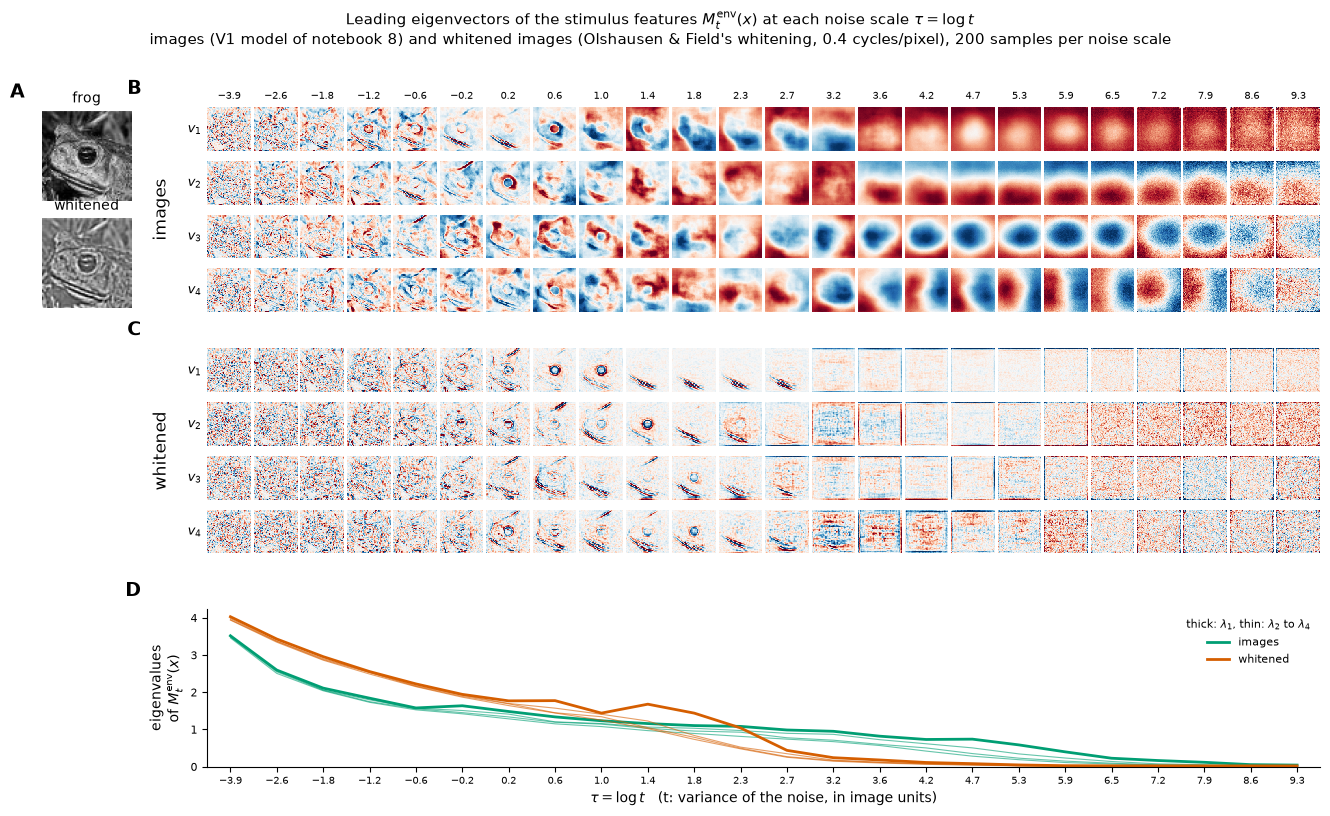

In [12]:
%%time

suptitle = (
    r"Leading eigenvectors of the stimulus features $M_t^{\rm env}(x)$ at each noise"
    r" scale $\tau = \log t$"
    "\nimages (V1 model of notebook 8) and whitened images (Olshausen & Field's"
    f" whitening, {whitening.cutoff:g} cycles/pixel), {PARAMS['n_samples']} samples"
    " per noise scale"
)
for name, (image, _) in examples.items():
    records = {"images": env["images"][name], "whitened": env["whitened"][name]}
    fig, _ = plot_per_scale(
        image.cpu(),
        records,
        PARAMS,
        name,
        suptitle,
        {},
        stimulus=("images", "whitened"),
        images={"whitened": whitened_examples[name][0]},
    )
    fig.savefig(
        figure_dir / f"stimulus_features_{name}.png",
        dpi=PARAMS["file_dpi"],
        bbox_inches="tight",
    )
    if name not in PARAMS["show"]:
        plt.close(fig)
print(len(examples), "figures saved in", figure_dir)

## 7. Conclusion

* **What we computed.** The whitening filter of Olshausen & Field (cut-off 0.4 cycles/pixel) of the TinyImageNet images, whose spectrum falls as $1/f^{2.33}$; a diffusion model of the whitened images, of the type of notebook 8's, trained on the null token only (200 epochs, about 7 h, final loss 0.084 against 0.056 for the V1 model); and the stimulus features of the frog and 12 test images from both models, with notebook 8's settings and seeds (about 26 min). The figures are in `assets/figures/stimulus_whitening/stimulus_features/`.
* **Whitening removes the coarse stimulus features.** For the images, the leading eigenvector moves from fine to coarse patterns as the noise grows: its mean spatial frequency (median over the 13 images) falls from 0.29 cycles/pixel at $\tau = -3.9$ to 0.03 at $\tau = 2.7$. For the whitened images it stays at fine and middle frequencies, 0.28 to 0.12 cycles/pixel, at every noise scale: the whitened images have no coarse structure left for the features to follow.
* **The whitened features fade at a finer noise scale.** The leading eigenvalue (median over the images) is about the same at the finest scale (3.6 against 3.4), but falls faster: 0.29 against 1.03 at $\tau = 2.7$, and 0.08 against 0.73 at $\tau = 4.7$. Whitening moves the variance of the images from coarse to fine scales, so the model of the whitened images can tell less about them at coarse noise scales.
* **Caveats.** The whitened features are directions in the space of the whitened images, not of the images. At the coarsest scales ($\tau \gtrsim 7$) the eigenvalues of both are below 0.2 and their eigenvectors are mostly the noise of the probes.
* **Next steps.** Compare these features with those of V1 and V4 (notebook 8): if the neurons' features look more like the whitened ones, the early visual system may see a whitened version of the images.